In [ ]:
import pandas as pd

train = pd.read_csv('/train.csv', parse_dates=['Date'])
store = pd.read_csv('/store.csv')

/tmp/ipykernel_1369/521616628.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('/train.csv', parse_dates=['Date'])


In [ ]:
# Staple the shop's ID card onto every daily row
df = train.merge(store, on='Store', how='left')

print(df.shape)
df.head()

(1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[ns]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  object        
 10  Assortment                 1017209 non-null  object        
 11  CompetitionDistance        1014567 no

In [ ]:
df.isnull().sum()

,0
Store,0
DayOfWeek,0
Date,0
Sales,0
Customers,0
Open,0
Promo,0
StateHoliday,0
SchoolHoliday,0
StoreType,0


In [ ]:
(df['Promo2'] == 0).sum()

np.int64(508031)

In [ ]:
# Promo2 columns: no promo means nothing to record, so fill with 0
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)
df['PromoInterval'] = df['PromoInterval'].fillna('None')

# Competition distance: fill with the median (typical shop)
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(df['CompetitionDistance'].median())

df.isnull().sum()

,0
Store,0
DayOfWeek,0
Date,0
Sales,0
Customers,0
Open,0
Promo,0
StateHoliday,0
SchoolHoliday,0
StoreType,0


In [ ]:
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0)
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(0)

print(df.isnull().sum().sum())

0


In [ ]:
df[df['Open'] == 0]['Sales'].describe()

,Sales
count,172817.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


In [ ]:
df = df[df['Open'] == 1].copy()

print(df.shape)

(844392, 18)


In [ ]:
df.groupby('Promo')['Sales'].mean()

,Sales
Promo,
0,5929.407603
1,8228.281239


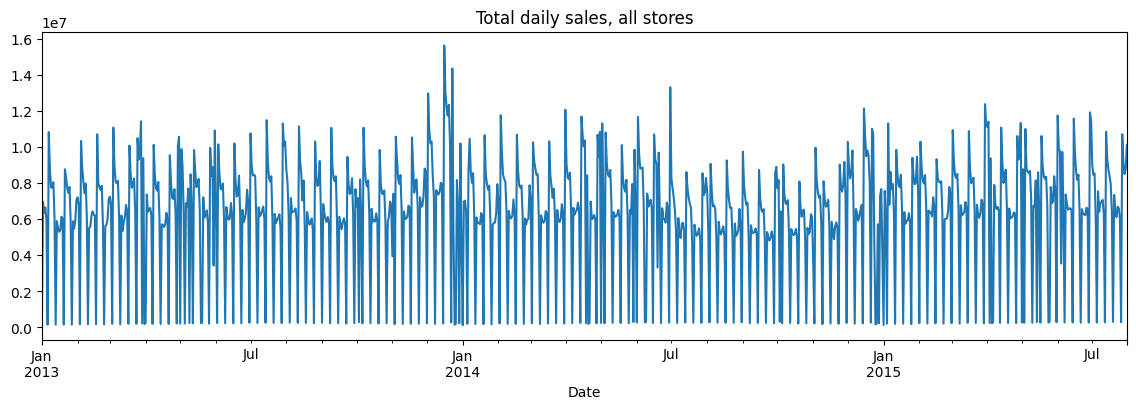

In [ ]:
import matplotlib.pyplot as plt

daily = df.groupby('Date')['Sales'].sum()

daily.plot(figsize=(14, 4), title='Total daily sales, all stores')
plt.show()

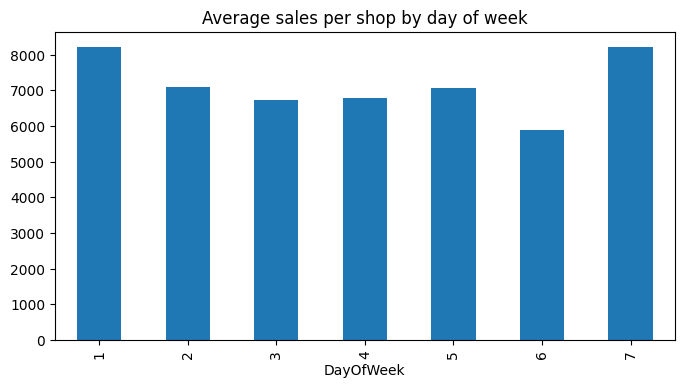

In [ ]:
df.groupby('DayOfWeek')['Sales'].mean().plot(kind='bar', figsize=(8, 4), title='Average sales per shop by day of week')
plt.show()


In [ ]:
df.groupby('DayOfWeek')['Store'].nunique()

,Store
DayOfWeek,
1,1115
2,1115
3,1115
4,1115
5,1115
6,1115
7,33


In [ ]:
df['StateHoliday'].value_counts()

,count
StateHoliday,
0,731342
0,112140
a,694
b,145
c,71


In [ ]:
df['StateHoliday'] = df['StateHoliday'].astype(str)
df['IsStateHoliday'] = (df['StateHoliday'] != '0').astype(int)

df['StateHoliday'].value_counts()

,count
StateHoliday,
0,843482
a,694
b,145
c,71


In [ ]:
df['IsStateHoliday'].sum()

np.int64(910)

In [ ]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

df[['Date', 'Year', 'Month', 'Day', 'WeekOfYear']].head()

,Date,Year,Month,Day,WeekOfYear
0,2015-07-31,2015,7,31,31
1,2015-07-31,2015,7,31,31
2,2015-07-31,2015,7,31,31
3,2015-07-31,2015,7,31,31
4,2015-07-31,2015,7,31,31


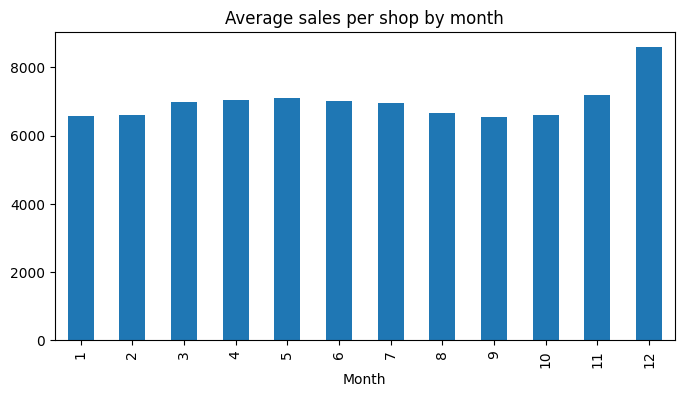

In [ ]:
df.groupby('Month')['Sales'].mean().plot(kind='bar', figsize=(8, 4), title='Average sales per shop by month')
plt.show()

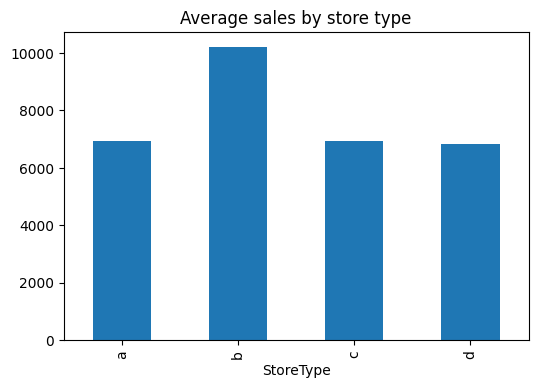

In [ ]:
df.groupby('StoreType')['Sales'].mean().plot(kind='bar', figsize=(6, 4), title='Average sales by store type')
plt.show()

In [ ]:
df.groupby('StoreType')['Store'].nunique()

,Store
StoreType,
a,602
b,17
c,148
d,348


In [ ]:
df = pd.get_dummies(df, columns=['StoreType', 'Assortment', 'StateHoliday', 'PromoInterval'])

print(df.shape)
df.head()

(844392, 34)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,...,Assortment_b,Assortment_c,StateHoliday_0,StateHoliday_a,StateHoliday_b,StateHoliday_c,"PromoInterval_Feb,May,Aug,Nov","PromoInterval_Jan,Apr,Jul,Oct","PromoInterval_Mar,Jun,Sept,Dec",PromoInterval_None
0,1,5,2015-07-31,5263,555,1,1,1,1270.0,9.0,...,False,False,True,False,False,False,False,False,False,True
1,2,5,2015-07-31,6064,625,1,1,1,570.0,11.0,...,False,False,True,False,False,False,False,True,False,False
2,3,5,2015-07-31,8314,821,1,1,1,14130.0,12.0,...,False,False,True,False,False,False,False,True,False,False
3,4,5,2015-07-31,13995,1498,1,1,1,620.0,9.0,...,False,True,True,False,False,False,False,False,False,True
4,5,5,2015-07-31,4822,559,1,1,1,29910.0,4.0,...,False,False,True,False,False,False,False,False,False,True


In [ ]:
df = df.drop(columns=['Customers', 'Open'])   # Open is always 1 now

cutoff = df['Date'].max() - pd.Timedelta(weeks=6)
train_df = df[df['Date'] <= cutoff]
valid_df = df[df['Date'] > cutoff]

print(train_df.shape, valid_df.shape)

(804110, 32) (40282, 32)


In [ ]:
from sklearn.metrics import mean_absolute_error

store_avg = train_df.groupby('Store')['Sales'].mean()
baseline_pred = valid_df['Store'].map(store_avg)

mae = mean_absolute_error(valid_df['Sales'], baseline_pred)
print('Baseline MAE:', mae)
print('As % of average sales:', mae / valid_df['Sales'].mean() * 100)

Baseline MAE: 1456.4352889431084
As % of average sales: 20.869907253335196


In [ ]:
!pip install lightgbm

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.787078 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 727
[LightGBM] [Info] Number of data points in the train set: 804110, number of used features: 30
[LightGBM] [Info] Start training from score 6954.355903
Model MAE: 929.8
Error % of average sales: 13.3
Baseline was: 20.9%


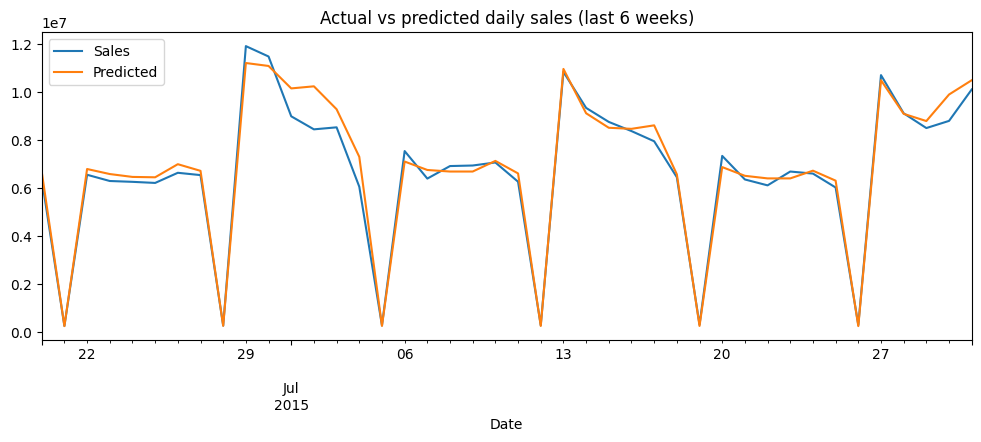

In [ ]:
import re
import matplotlib.pyplot as plt

# clean column names (remove commas/special characters)
clean = lambda c: re.sub(r'[^A-Za-z0-9_]', '_', c)
train_df = train_df.rename(columns=clean)
valid_df = valid_df.rename(columns=clean)

features = [c for c in train_df.columns if c not in ['Sales', 'Date']]

model = LGBMRegressor(n_estimators=300, learning_rate=0.1, random_state=42)
model.fit(train_df[features], train_df['Sales'])

pred = model.predict(valid_df[features])
mae = mean_absolute_error(valid_df['Sales'], pred)
print('Model MAE:', round(mae, 1))
print('Error % of average sales:', round(mae / valid_df['Sales'].mean() * 100, 1))
print('Baseline was: 20.9%')

# predicted vs actual, total sales per day
check = valid_df[['Date', 'Sales']].copy()
check['Predicted'] = pred
check.groupby('Date')[['Sales', 'Predicted']].sum().plot(figsize=(12, 4), title='Actual vs predicted daily sales (last 6 weeks)')
plt.show()

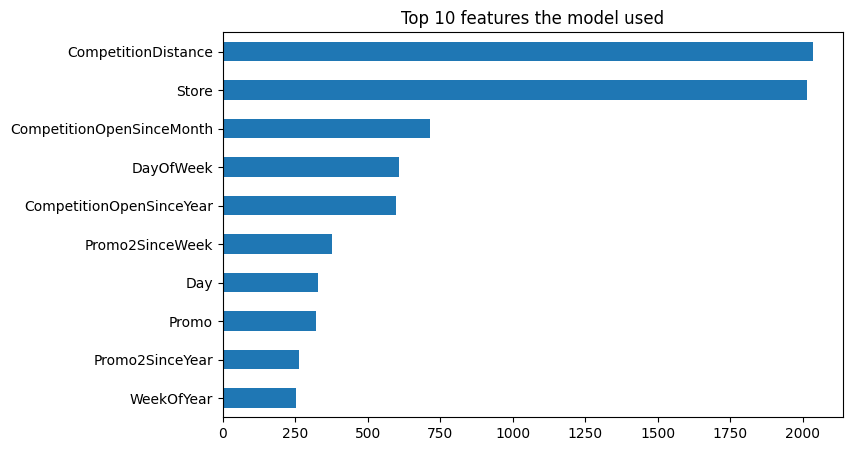

In [ ]:
imp = pd.Series(model.feature_importances_, index=features).sort_values()
imp.tail(10).plot(kind='barh', figsize=(8, 5), title='Top 10 features the model used')
plt.show()

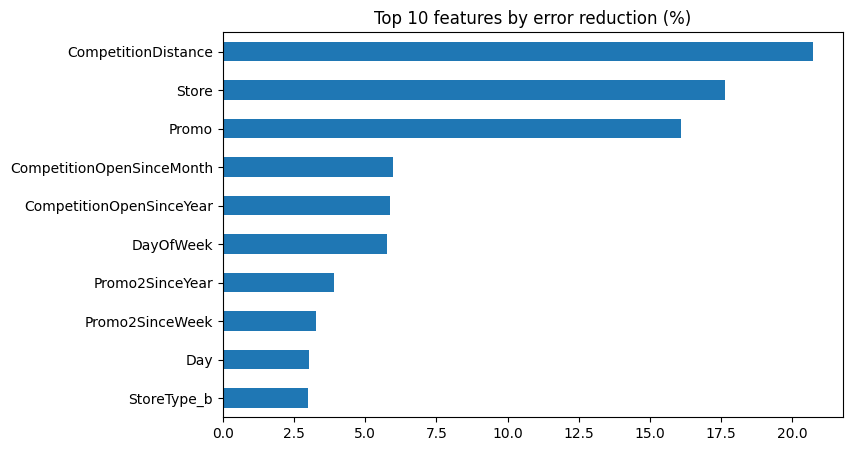

In [ ]:
imp = pd.Series(
    model.booster_.feature_importance(importance_type='gain'),
    index=features
).sort_values()

(imp / imp.sum() * 100).tail(10).plot(kind='barh', figsize=(8, 5), title='Top 10 features by error reduction (%)')
plt.show()

In [ ]:
cats = sorted(train_df['Store'].unique())

train_df = train_df.copy()
valid_df = valid_df.copy()
train_df['Store'] = pd.Categorical(train_df['Store'], categories=cats)
valid_df['Store'] = pd.Categorical(valid_df['Store'], categories=cats)

model2 = LGBMRegressor(n_estimators=300, learning_rate=0.1, random_state=42)
model2.fit(train_df[features], train_df['Sales'])

pred2 = model2.predict(valid_df[features])
mae2 = mean_absolute_error(valid_df['Sales'], pred2)
print('New error %:', round(mae2 / valid_df['Sales'].mean() * 100, 1))
print('Previous was: 13.3%')

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.105738 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1573
[LightGBM] [Info] Number of data points in the train set: 804110, number of used features: 30
[LightGBM] [Info] Start training from score 6954.355903
New error %: 9.0
Previous was: 13.3%


In [ ]:
# readable version of the data, open days only
dash = train.merge(store, on='Store', how='left')
dash = dash[dash['Open'] == 1].copy()
dash['StateHoliday'] = dash['StateHoliday'].astype(str)

dash['Year'] = dash['Date'].dt.year
dash['Month'] = dash['Date'].dt.month
dash['MonthName'] = dash['Date'].dt.month_name()
dash['DayName'] = dash['Date'].dt.day_name()
dash['PromoLabel'] = dash['Promo'].map({0: 'No Promo', 1: 'Promo'})

# add model predictions (only exist for the last 6 weeks)
pred_df = pd.DataFrame({'Store': valid_df['Store'].astype(int),
                        'Date': valid_df['Date'],
                        'Predicted': pred2})
dash = dash.merge(pred_df, on=['Store', 'Date'], how='left')

dash.to_csv('rossmann_dashboard.csv', index=False)
print(dash.shape)

(844392, 24)
